# 03. CNN з нуля

Навчаємо невелику згорткову мережу і перевіряємо, чи допомагають аугментація та ваги класів. Так ми дізнаємось, що дає нейромережа порівняно з класичним ML з notebook 02.

1. Підготовка даних і датасету з аугментацією.
2. Архітектура мережі.
3. Функція навчання з ранньою зупинкою.
4. Чотири експерименти: без нічого, з аугментацією, з вагами класів, з обома.
5. Порівняння результатів.

### 1) Імпорти, шляхи, seed, пристрій

Підключаємо бібліотеки, шляхи і `SEED = 42`. Функція `set_seed` фіксує випадковість у Python, NumPy і PyTorch, щоб кожен експеримент починався з однакових умов. Також вибираємо пристрій: GPU, якщо він є, інакше CPU.

In [1]:
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

DATA_DIR = Path("../data/chest_xray")
RESULTS_DIR = Path("../results")
SEED = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій:", device)

def set_seed(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

Пристрій: cpu


### 2) Завантаження даних

Читаємо розбиття `splits.csv` і кеш знімків 128 × 128, створений в notebook 02. Перевірка `assert` гарантує, що кеш і таблиця мають однакову кількість рядків, тобто знімок `x` справді відповідає рядку `x`. Далі створюємо маски train/val/test і вектор міток.

In [ ]:
df = pd.read_csv(RESULTS_DIR / "splits.csv")
df["y"] = (df["label"] == "PNEUMONIA").astype(int)

X_img = np.load(DATA_DIR.parent / "cache_128.npz")["X"] 
assert len(X_img) == len(df), "Кеш і splits.csv не збігаються"

tr = (df["new_split"] == "train").values
va = (df["new_split"] == "val").values
te = (df["new_split"] == "test").values
y = df["y"].values

print("train:", tr.sum(), "| val:", va.sum(), "| test:", te.sum())

train: 4160 | val: 1072 | test: 624


Розбиття те саме, що в notebook 02: 4 160 / 1 072 / 624.

### 3) Аугментація і датасет

**Аугментація** робить з одного знімка трохи різні варіанти, щоб мережа не запам'ятовувала конкретні знімки. Використовуємо невеликі зміни, які реалістично трапляються на рентгені: поворот до 10°, зсув до 5%, масштаб 0,9-1,1, зміна яскравості і контрасту на 20%.

Клас `XrayDataset` віддає мережі один знімок: перетворює його в тензор зі значеннями 0-1, за потреби застосовує аугментацію і нормує в діапазон від -1 до 1. Аугментацію вмикаємо тільки для train, а val і test залишаються без змін.

In [ ]:
augment_tf = T.Compose([
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.2, contrast=0.2),
])

class XrayDataset(Dataset):
    def __init__(self, X, y, transform=None):
        self.X, self.y, self.transform = X, y, transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float().div(255).unsqueeze(0)
        if self.transform is not None:
            x = self.transform(x)
        x = (x - 0.5) / 0.5 
        return x, torch.tensor(self.y[i], dtype=torch.float32)

### 4) Архітектура мережі

Мережа складається з чотирьох однакових блоків: згортка 3 × 3, `BatchNorm` (стабілізує навчання), `ReLU` і `MaxPool` (зменшує розмір удвічі). Кількість каналів зростає: 16 → 32 → 64 → 128, тобто спочатку мережа бачить прості контури, потім складніші форми.

Після блоків іде `AdaptiveAvgPool` (усереднює карту ознак у одне число на канал), `Dropout(0.3)` проти перенавчання і один вихідний нейрон. Він дає одне число (логіт), яке `sigmoid` перетворює в ймовірність пневмонії. Мережа маленька: менше 100 тисяч параметрів, бо даних небагато.

In [4]:
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(block(1, 16), block(16, 32), block(32, 64), block(64, 128))
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

print(sum(p.numel() for p in SimpleCNN().parameters()), "параметрів")

97761 параметрів


### 5) Передбачення і метрики

- `predict` проганяє дані через мережу без обчислення градієнтів і повертає ймовірності та справжні мітки.
- `compute_metrics` перетворює ймовірності в класи за порогом 0,5 і рахує ті самі метрики, що в notebook 02: accuracy, precision, recall, specificity, F1.

In [5]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    for xb, yb in loader:
        probs.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
        ys.append(yb.numpy())
    return np.concatenate(probs), np.concatenate(ys).astype(int)

def compute_metrics(y_true, probs, threshold=0.5):
    pred = (probs >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred),
        "specificity": recall_score(y_true, pred, pos_label=0),
        "f1": f1_score(y_true, pred),
    }

### 6) Функція навчання одного експерименту

`run_experiment` навчає мережу з заданими налаштуваннями (з аугментацією чи без, з вагами класів чи без). Що в ній відбувається:

- Оптимізатор Adam, `lr = 1e-3`, пачки по 32 знімки. На початку викликаємо `set_seed`, тож усі експерименти порівнюються в однакових умовах.
- Функція втрат `BCEWithLogitsLoss`. З `use_weights` додається `pos_weight`, що рівний відношенню кількості здорових до хворих у train. Воно менше за 1, тож помилки на частому класі (пневмонія) коштують менше, і баланс вирівнюється.
- Після кожної епохи рахуємо val loss і val F1, щоб бачити, як мережа працює на даних, яких не бачила.
- **Рання зупинка:** якщо val F1 не покращується 5 епох поспіль, навчання припиняється. Найкращі ваги за val F1 запам'ятовуються і в кінці відновлюються, тож береться найкраща епоха, а не остання.
- У кінці модель зберігається у `.pth`, а метрики рахуються на val і test.

In [ ]:
def run_experiment(name, augment, use_weights, epochs=15, lr=1e-3, patience=5):
    set_seed(SEED)

    train_ds = XrayDataset(X_img[tr], y[tr], augment_tf if augment else None)
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
    val_loader = DataLoader(XrayDataset(X_img[va], y[va]), batch_size=64)
    test_loader = DataLoader(XrayDataset(X_img[te], y[te]), batch_size=64)

    model = SimpleCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    if use_weights:
        pw = torch.tensor([(y[tr] == 0).sum() / (y[tr] == 1).sum()], dtype=torch.float32).to(device)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    else:
        criterion = nn.BCEWithLogitsLoss()

    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state, bad_epochs = -1, None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(train_ds)

        val_probs, val_y = predict(model, val_loader)
        eps = 1e-7
        val_loss = float(-np.mean(val_y * np.log(val_probs + eps) + (1 - val_y) * np.log(1 - val_probs + eps)))
        val_f1 = f1_score(val_y, (val_probs >= 0.5).astype(int))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_f1"].append(val_f1)
        print(f"[{name}] епоха {epoch:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val F1 {val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1, best_state, bad_epochs = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"Ранню зупинку: {patience} епох без покращення")
                break

    model.load_state_dict(best_state) 
    torch.save(best_state, RESULTS_DIR / f"{name}.pth")

    val_probs, val_y = predict(model, val_loader)
    test_probs, test_y = predict(model, test_loader)
    return {
        "name": name, "history": history,
        "val": compute_metrics(val_y, val_probs),
        "test": compute_metrics(test_y, test_probs),
        "test_probs": test_probs, "test_y": test_y,
    }

### 7) Запуск чотирьох експериментів

Навчаємо чотири варіанти однієї й тієї ж мережі: без нічого, з аугментацією, з вагами класів, з аугментацією і вагами. Так видно внесок кожного прийому окремо і разом. Максимум 15 епох.

In [7]:
configs = [
    ("cnn_plain",        False, False),
    ("cnn_aug",          True,  False),
    ("cnn_weights",      False, True),
    ("cnn_aug_weights",  True,  True),
]

results = {}
for name, aug, w in configs:
    results[name] = run_experiment(name, augment=aug, use_weights=w, epochs=15)

[cnn_plain] епоха  1 | train loss 0.2474 | val loss 0.6961 | val F1 0.8604
[cnn_plain] епоха  2 | train loss 0.1482 | val loss 0.8146 | val F1 0.7219
[cnn_plain] епоха  3 | train loss 0.1301 | val loss 0.1828 | val F1 0.9524
[cnn_plain] епоха  4 | train loss 0.1105 | val loss 1.2208 | val F1 0.6413
[cnn_plain] епоха  5 | train loss 0.1027 | val loss 0.9877 | val F1 0.7069
[cnn_plain] епоха  6 | train loss 0.1017 | val loss 0.3692 | val F1 0.8977
[cnn_plain] епоха  7 | train loss 0.0740 | val loss 0.1124 | val F1 0.9712
[cnn_plain] епоха  8 | train loss 0.0760 | val loss 0.1735 | val F1 0.9505
[cnn_plain] епоха  9 | train loss 0.0681 | val loss 0.3701 | val F1 0.8863
[cnn_plain] епоха 10 | train loss 0.0619 | val loss 3.0825 | val F1 0.1196
[cnn_plain] епоха 11 | train loss 0.0837 | val loss 0.0992 | val F1 0.9812
[cnn_plain] епоха 12 | train loss 0.0630 | val loss 0.0592 | val F1 0.9877
[cnn_plain] епоха 13 | train loss 0.0523 | val loss 0.1416 | val F1 0.9685
[cnn_plain] епоха 14 | tr

Без аугментації навчання йшло всі 15 епох, а з нею рання зупинка спрацювала на 12-й (`cnn_aug`) і 13-й (`cnn_aug_weights`) епохах. Бачимо, що val loss і val F1 стрибають між епохами. Тому вибір найкращої епохи за val F1 тут важливий.

### 8) Таблиця результатів

Збираємо метрики всіх чотирьох моделей на val і test в одну таблицю.

In [8]:
names = {
    "cnn_plain": "CNN",
    "cnn_aug": "CNN + аугментація",
    "cnn_weights": "CNN + ваги класів",
    "cnn_aug_weights": "CNN + аугментація + ваги",
}

rows = []
for key, r in results.items():
    for split in ["val", "test"]:
        rows.append({"model": names[key], "split": split, **r[split]})

metrics_cnn = pd.DataFrame(rows)
metrics_cnn.to_csv(RESULTS_DIR / "metrics_cnn.csv", index=False)
metrics_cnn.round(3)

,model,split,accuracy,precision,recall,specificity,f1
0,CNN,val,0.981,0.978,0.998,0.933,0.988
1,CNN,test,0.710,0.683,1.000,0.226,0.812
2,CNN + аугментація,val,0.963,0.972,0.979,0.915,0.975
3,CNN + аугментація,test,0.779,0.744,0.985,0.436,0.848
4,CNN + ваги класів,val,0.975,0.978,0.989,0.933,0.983
5,CNN + ваги класів,test,0.744,0.711,0.992,0.329,0.829
6,CNN + аугментація + ваги,val,0.962,0.973,0.976,0.919,0.974
7,CNN + аугментація + ваги,test,0.804,0.767,0.987,0.500,0.863


**Результат:** на val усі моделі хороші (accuracy 0,96-0,98, F1 0,97-0,99), а на test значно гірше (accuracy 0,71-0,80). Recall скрізь майже ідеальний (0,985-1,0), а specificity низька (0,23-0,50), тобто багато здорових знімків модель називає хворими.

Аугментація і ваги класів покращують test: `CNN` має accuracy 0,710 і specificity 0,226, а `CNN + аугментація + ваги` має 0,804 і 0,500. На val цього не видно, але на test ефект помітний. Це знову показує, що val для цієї задачі завищує якість.

### 9) Криві навчання

Будуємо графіки val loss і val F1 по епохах для всіх моделей, щоб побачити, наскільки навчання стабільне.

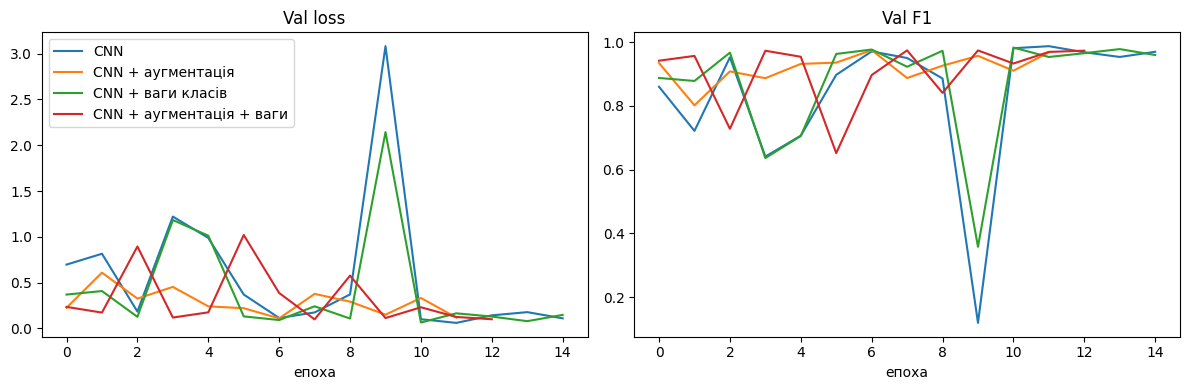

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, r in results.items():
    axes[0].plot(r["history"]["val_loss"], label=names[key])
    axes[1].plot(r["history"]["val_f1"], label=names[key])

axes[0].set_title("Val loss"); axes[0].set_xlabel("епоха"); axes[0].legend()
axes[1].set_title("Val F1");   axes[1].set_xlabel("епоха")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cnn_curves.png", dpi=150)
plt.show()

Криві нестабільні: val loss і F1 різко стрибають між епохами (особливо без аугментації). Через це val F1 одного разу може бути випадково високим, а різниця між моделями на val лежить у межах цього шуму.

### 10) Матриця помилок найкращої моделі

Вибираємо модель з найбільшим F1 на val (так само, як раніше, не за test) і будуємо для неї матрицю помилок на test.

Найкраща за val F1: CNN


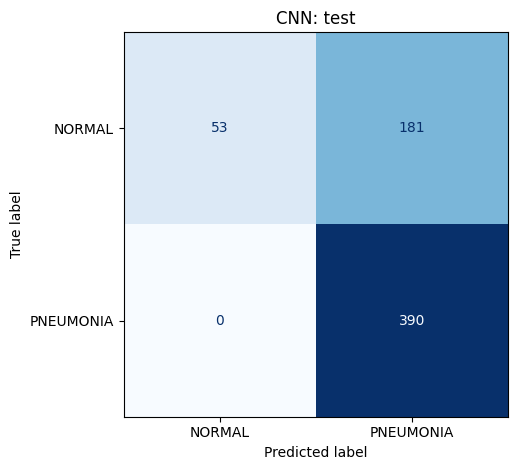

In [ ]:
best_key = max(results, key=lambda k: results[k]["val"]["f1"])   
print("Найкраща за val F1:", names[best_key])

r = results[best_key]
cm = confusion_matrix(r["test_y"], (r["test_probs"] >= 0.5).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["NORMAL", "PNEUMONIA"]).plot(cmap="Blues", colorbar=False)
plt.title(f"{names[best_key]}: test")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "cm_cnn_best.png", dpi=150)
plt.show()

Найкращою за val F1 стала проста `CNN` (F1 0,988). На test вона знаходить усіх хворих (recall 1,0), але хибно позначає пневмонією 181 здорового з 234 (specificity 0,226). Тобто за val F1 вибрана модель, яка на test найгірша за accuracy. Це наслідок того, що val занадто легкий і різниця між моделями на ньому мала.

## Підсумок

**Що зроблено**
- Побудували невелику CNN (менше 100 тисяч параметрів) і навчили її в чотирьох варіантах: без доповнень, з аугментацією, з вагами класів, з обома.
- Використали раннє зупинення за val F1 і відновлення найкращих ваг.

**Висновки**
- На val accuracy 0,96-0,98, на test лише 0,71-0,80. Recall майже ідеальний, specificity низька (0,23-0,50).
- Аугментація і ваги класів покращують test (найкраща `CNN + аугментація + ваги`: accuracy 0,804), але CNN з нуля лише ненабагато краща за SVM на сирих пікселях (0,795).
- Навчання нестабільне, а вибір за val F1 орієнтовний. 